# 323 Active Caspase Compounds — Structural Clustering

Cluster all **323 caspase-active compounds** (66 pure-Active + 257 Mixed-with-Active)
from the merged 14-cell-line dataset using the standard cheminformatics pipeline.

**Pipeline**
1. **ECFP4 fingerprints** — `rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)`
2. **UMAP projection** — `n_neighbors=min(15, n-1)`, `min_dist=0.3`, `metric='jaccard'`, `random_state=42`
3. **DBSCAN clustering** — eps auto-selected via Kneedle algorithm on sorted k-NN distances in UMAP space
4. **MCS common cores** — `rdFMCS.FindMCS(mols, ringMatchesRingOnly=True, completeRingsOnly=True, timeout=10)`
5. **Grid visualisation** — representative structures + MCS core per cluster

**Behaviour categories in this subset**
| Category | Rule | Colour |
|---|---|---|
| Active | behavior == 'Active' | red `#d62728` |
| Mixed (with Active) | 'Active' in behavior, not pure Active | orange `#ff7f0e` |

In [61]:
import warnings
warnings.filterwarnings('ignore')
#add 7000 compunds to dataset and spot those cell line active in this 
import os, glob
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from rdkit.Chem.Draw import rdMolDraw2D

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

from kneed import KneeLocator
import umap

# ── colour map ──────────────────────────────────────────────────────────────
COLOR_MAP = {
    'Active':                      '#d62728',
    'Mixed (with Active)':         '#ff7f0e',
    'Inconclusive':                '#9467bd',
    'Mixed (Inactive/Inconclusive)':'#8c564b',
    'Inactive':                    '#aec7e8',
}

# ── helper: fingerprint matrix ──────────────────────────────────────────────
def to_fp_matrix(mols):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fps = [gen.GetFingerprint(m) for m in mols]
    arr = np.zeros((len(fps), 2048), dtype=np.uint8)
    for i, fp in enumerate(fps):
        DataStructs.ConvertToNumpyArray(fp, arr[i])
    return fps, arr

# ── helper: UMAP scatter ─────────────────────────────────────────────────────
def plot_umap(fp_matrix, labels, title, color_map,
              annotate=None, annotate_mask=None,
              s=12, alpha=0.55):
    n = len(fp_matrix)
    nn = min(15, n - 1)
    reducer = umap.UMAP(n_neighbors=nn, min_dist=0.3,
                        metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    fig, ax = plt.subplots(figsize=(11, 8))
    for cat, col in color_map.items():
        mask = np.array(labels) == cat
        ax.scatter(emb[mask, 0], emb[mask, 1],
                   c=col, label=cat, s=s, alpha=alpha, linewidths=0)
    if annotate is not None and annotate_mask is not None:
        for idx in np.where(annotate_mask)[0]:
            ax.annotate(str(annotate[idx]), (emb[idx, 0], emb[idx, 1]),
                        fontsize=6, alpha=0.75)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
    ax.legend(loc='best', markerscale=2, fontsize=8)
    plt.tight_layout(); plt.show()
    return emb

# ── helper: MCS core ─────────────────────────────────────────────────────────
def get_mcs_core(mols):
    """
    Return a clean, drawable MCS core mol (no query atoms/bonds).

    Chem.MolFromSmarts() sets hasQuery=True on every atom and bond even when
    the atomic number is well-defined.  RDKit's drawing engine renders any
    query atom/bond as '?', so we rebuild the molecule from scratch using plain
    Chem.Atom objects — which have hasQuery=False by default.
    """
    if len(mols) < 2:
        return None
    try:
        res = rdFMCS.FindMCS(mols,
                             ringMatchesRingOnly=True,
                             completeRingsOnly=True,
                             timeout=10)
        if not res or not res.smartsString or res.numAtoms == 0:
            return None
        smarts_mol = Chem.MolFromSmarts(res.smartsString)
        if smarts_mol is None:
            return None

        # Rebuild as a plain (non-query) molecule so hasQuery=False on all
        # atoms and bonds → no '?' symbols when drawn.
        rw = Chem.RWMol()
        for atom in smarts_mol.GetAtoms():
            anum = atom.GetAtomicNum() or 6   # default unknown to carbon
            rw.AddAtom(Chem.Atom(anum))
        for bond in smarts_mol.GetBonds():
            bt = bond.GetBondType()
            if bt == Chem.BondType.UNSPECIFIED:
                bt = Chem.BondType.SINGLE
            rw.AddBond(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bt)
        try:
            Chem.SanitizeMol(rw)
            return rw.GetMol()
        except Exception:
            return smarts_mol   # last-resort fallback
    except Exception:
        return None

# ── helper: pick representatives closest to centroid ─────────────────────────
def pick_central(sub, n_min=3, n_max=5):
    xy = sub[['umap_x', 'umap_y']].values
    centroid = xy.mean(axis=0)
    dists = np.linalg.norm(xy - centroid, axis=1)
    n = max(n_min, min(n_max, len(sub)))
    idx = np.argsort(dists)[:n]
    return sub.iloc[idx]

# ── helper: k-NN eps plot ────────────────────────────────────────────────────
def knn_eps_plot(emb, min_samples=5, title='k-NN Distance Plot'):
    k = min_samples
    nbrs = NearestNeighbors(n_neighbors=k).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, k - 1])[::-1]
    kl = KneeLocator(range(len(sorted_d)), sorted_d,
                     curve='convex', direction='decreasing')
    eps = sorted_d[kl.knee] if kl.knee is not None else sorted_d[int(len(sorted_d) * 0.1)]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(sorted_d, lw=1.5)
    ax.axhline(eps, color='red', ls='--', lw=1.2, label=f'eps = {eps:.4f}')
    if kl.knee is not None:
        ax.axvline(kl.knee, color='orange', ls=':', lw=1.2, label=f'knee @ {kl.knee}')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Points sorted by distance (desc)')
    ax.set_ylabel(f'{k}-NN distance (UMAP space)')
    ax.legend()
    plt.tight_layout(); plt.show()
    print(f'Auto-selected eps = {eps:.4f}')
    return sorted_d, eps

# ── helper: draw cluster representatives ────────────────────────────────────
def draw_cluster_reps(dataset, title, mols_per_row=5,
                       img_size=(250, 200), max_per_cluster=5,
                       max_clusters=20):
    cl_name_map = {}
    clusters = sorted([c for c in dataset['cluster'].unique() if c != -1])
    if len(clusters) > max_clusters:
        clusters = clusters[:max_clusters]
    all_mols, all_labels, all_highlights = [], [], []
    for cl in clusters:
        sub = dataset[dataset['cluster'] == cl].copy()
        n_total = len(sub)
        n_active = (sub['behavior_category'] == 'Active').sum()
        n_mixed  = sub['behavior_category'].str.contains('Active').sum() - n_active
        reps = pick_central(sub, n_min=1, n_max=max_per_cluster)
        core = get_mcs_core([r for r in reps['mol'].tolist() if r is not None])
        cl_label = f'C{cl}'
        cl_name_map[cl] = cl_label
        if core is not None:
            all_mols.append(core)
            all_labels.append(f'{cl_label} MCS-core')
            all_highlights.append({})
        for _, row in reps.iterrows():
            if row['mol'] is None:
                continue
            cid = row['PUBCHEM_CID']
            all_mols.append(row['mol'])
            all_labels.append(
                f'C{cl} n={n_total} act={n_active} mix={n_mixed} | CID {cid}')
            if core is not None:
                try:
                    hit = row['mol'].GetSubstructMatch(core)
                    all_highlights.append({a: (0.9, 0.6, 0.1) for a in hit})
                except Exception:
                    all_highlights.append({})
            else:
                all_highlights.append({})
    if not all_mols:
        print('No molecules to draw.')
        return cl_name_map
    img = Draw.MolsToGridImage(
        all_mols,
        molsPerRow=mols_per_row,
        subImgSize=img_size,
        legends=all_labels,
        highlightAtomLists=[list(h.keys()) for h in all_highlights],
        returnPNG=False,
    )
    plt.figure(figsize=(mols_per_row * img_size[0] / 72,
                        ((len(all_mols) // mols_per_row + 1) * img_size[1]) / 72))
    plt.title(title, fontsize=12)
    plt.imshow(img)
    plt.axis('off')
    plt.tight_layout(); plt.show()
    return cl_name_map

# ── helper: UMAP coloured by cluster ────────────────────────────────────────
def umap_by_cluster(dataset, cl_name_map, title='UMAP by Cluster'):
    fig, ax = plt.subplots(figsize=(11, 8))
    noise_mask = dataset['cluster'] == -1
    ax.scatter(dataset.loc[noise_mask, 'umap_x'],
               dataset.loc[noise_mask, 'umap_y'],
               c='lightgrey', s=8, alpha=0.4, linewidths=0, label='Noise')
    cmap = plt.cm.get_cmap('tab20', max(len(cl_name_map), 1))
    handles = [mpatches.Patch(color='lightgrey', label='Noise (-1)')]
    for i, (cl, name) in enumerate(sorted(cl_name_map.items())):
        mask = dataset['cluster'] == cl
        col = cmap(i)
        ax.scatter(dataset.loc[mask, 'umap_x'],
                   dataset.loc[mask, 'umap_y'],
                   c=[col], s=12, alpha=0.65, linewidths=0)
        handles.append(mpatches.Patch(color=col, label=name))
    ax.legend(handles=handles, loc='best', fontsize=7,
              ncol=max(1, len(cl_name_map) // 20 + 1))
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
    plt.tight_layout(); plt.show()

print('Setup complete.')

Setup complete.


---
## Load Data

Read the 7,716-compound main CSV, join SMILES from all cleaned-dataset CSVs,
parse RDKit mols and compute ECFP4 fingerprints, then **subset to the 323 active compounds**
(behavior_category in {Active, Mixed (with Active)}).

In [62]:
BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'

# ── main table ──────────────────────────────────────────────────────────────
main_csv = BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv'
gall = pd.read_csv(main_csv)
print(f'Main CSV: {gall.shape[0]} rows x {gall.shape[1]} cols')
print('Columns:', list(gall.columns))

# ── collect SMILES from all cleaned_datasets CSVs ───────────────────────────
smiles_frames = []
for fp in glob.glob(BASE + 'cleaned_datasets/*.csv'):
    try:
        tmp = pd.read_csv(fp, usecols=lambda c: c in
                          ['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
        if 'PUBCHEM_CID' in tmp.columns and 'PUBCHEM_EXT_DATASOURCE_SMILES' in tmp.columns:
            smiles_frames.append(tmp.dropna())
    except Exception as e:
        print(f'  skipped {os.path.basename(fp)}: {e}')

smiles_df = pd.concat(smiles_frames, ignore_index=True)
smiles_df = (smiles_df
             .drop_duplicates('PUBCHEM_CID')
             .rename(columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'SMILES'}))
print(f'SMILES pool: {len(smiles_df)} unique CIDs')

# ── merge ───────────────────────────────────────────────────────────────────
gall = gall.merge(smiles_df[['PUBCHEM_CID', 'SMILES']], on='PUBCHEM_CID', how='left')
print(f'After merge — SMILES available for '
      f"{gall['SMILES'].notna().sum()} / {len(gall)} compounds")

# ── behavior categories ──────────────────────────────────────────────────────
def assign_category(b):
    if b == 'Active':
        return 'Active'
    if b == 'Inactive':
        return 'Inactive'
    if b == 'Inconclusive':
        return 'Inconclusive'
    if 'Active' in str(b):
        return 'Mixed (with Active)'
    return 'Mixed (Inactive/Inconclusive)'

gall['behavior_category'] = gall['behavior'].apply(assign_category)
print('\nBehavior category breakdown:')
print(gall['behavior_category'].value_counts().to_string())

# ── parse mols + fingerprints ────────────────────────────────────────────────
gall['mol'] = gall['SMILES'].apply(
    lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None)
n_valid = gall['mol'].notna().sum()
print(f'\nValid RDKit mols: {n_valid} / {len(gall)}')

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def safe_fp(mol):
    try:
        return gen.GetFingerprint(mol) if mol is not None else None
    except Exception:
        return None

gall['fp'] = gall['mol'].apply(safe_fp)
print(f'Fingerprints computed: {gall["fp"].notna().sum()}')

Main CSV: 7716 rows x 17 cols
Columns: ['PUBCHEM_CID', 'AID_1346980', 'AID_655', 'AID_656', 'AID_657', 'AID_658', 'AID_659', 'AID_660', 'AID_661', 'AID_663', 'AID_664', 'AID_665', 'AID_666', 'AID_667', 'combined_hepg2_casepase.csv', 'pattern', 'behavior']
SMILES pool: 8777 unique CIDs
After merge — SMILES available for 7716 / 7716 compounds

Behavior category breakdown:
behavior_category
Inactive                         6967
Mixed (Inactive/Inconclusive)     359
Mixed (with Active)               257
Inconclusive                       67
Active                             66

Valid RDKit mols: 7716 / 7716
Fingerprints computed: 7716


[13:30:24] WARNING: not removing hydrogen atom without neighbors


---
## Section 1 — Chemical Space Overview (323 Active Compounds)

UMAP projection coloured by behaviour category (Active vs Mixed-with-Active).
Points are drawn without CID annotations to keep the plot clean.
This establishes the structural landscape before clustering.

Active compounds: 323
behavior_category
Mixed (with Active)    257
Active                  66


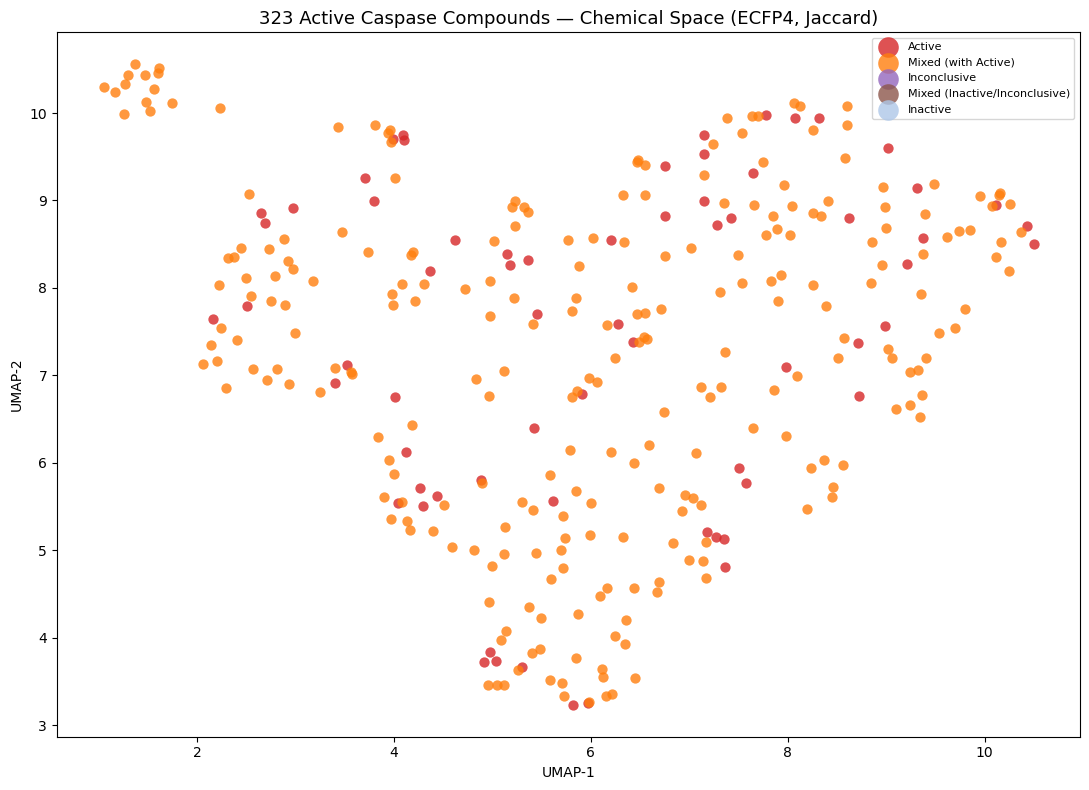

Embedding complete (323 points).


In [63]:
# Subset to active compounds (Active + Mixed with Active)
g323 = gall[gall['behavior_category'].isin(
    ['Active', 'Mixed (with Active)'])].copy().reset_index(drop=True)
print(f'Active compounds: {len(g323)}')
print(g323['behavior_category'].value_counts().to_string())

fps_323, fp_matrix_323 = to_fp_matrix(g323['mol'].tolist())
g323['fp'] = fps_323

emb_323 = plot_umap(
    fp_matrix_323,
    labels    = g323['behavior_category'].tolist(),
    title     = '323 Active Caspase Compounds — Chemical Space (ECFP4, Jaccard)',
    color_map = COLOR_MAP,
    s=55, alpha=0.80,
)
g323['umap_x'] = emb_323[:, 0]
g323['umap_y'] = emb_323[:, 1]
print(f'Embedding complete ({len(g323)} points).')

---
## Section 2 — DBSCAN Clustering

Density-based clustering applied in the 2-D UMAP space of the 323 active compounds.
**eps** is auto-selected via the **Kneedle** algorithm on the sorted k-NN distance curve.
`min_samples=3` is used (appropriate for this set size: n≈300).
Points that cannot be assigned to any cluster are labelled as noise (cluster = −1).

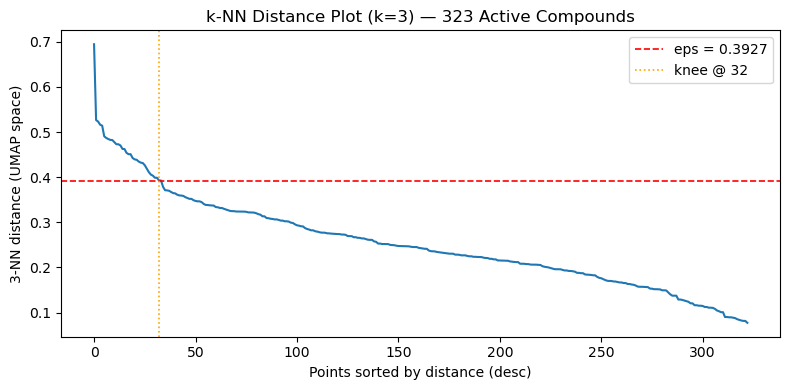

Auto-selected eps = 0.3927


In [64]:
MIN_SAMPLES = 3

sorted_d, eps = knn_eps_plot(
    emb_323, min_samples=MIN_SAMPLES,
    title=f'k-NN Distance Plot (k={MIN_SAMPLES}) — 323 Active Compounds')

In [65]:
db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(emb_323)
g323['cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise    = (db.labels_ == -1).sum()
print(f'DBSCAN: {n_clusters} clusters, {n_noise} noise points '
      f'({100*n_noise/len(g323):.1f}%)')

cl_sizes = pd.Series(db.labels_[db.labels_ != -1]).value_counts()
print(f'Cluster sizes — min: {cl_sizes.min()}, max: {cl_sizes.max()}, '
      f'median: {cl_sizes.median():.0f}')

DBSCAN: 14 clusters, 15 noise points (4.6%)
Cluster sizes — min: 3, max: 90, median: 8


---
## Section 3 — Cluster Composition Analysis

For each DBSCAN cluster, count Active vs Mixed-with-Active members.
Clusters ranked by pure-active fraction reveal scaffolds most reliably
associated with caspase activation across cell lines.

In [66]:
cats = ['Active', 'Mixed (with Active)']

rows = []
for cl in sorted(g323['cluster'].unique()):
    sub = g323[g323['cluster'] == cl]
    row = {'cluster': cl, 'total': len(sub)}
    for cat in cats:
        row[cat] = (sub['behavior_category'] == cat).sum()
    row['active_frac'] = row['Active'] / len(sub)
    row['active_total'] = row['Active'] + row['Mixed (with Active)']
    rows.append(row)

comp_df = pd.DataFrame(rows).sort_values('active_frac', ascending=False)
print('Clusters ranked by pure-active fraction:')
print(comp_df.to_string(index=False))

Clusters ranked by pure-active fraction:
 cluster  total  Active  Mixed (with Active)  active_frac  active_total
       9      3       2                    1     0.666667             3
      -1     15       6                    9     0.400000            15
       7      8       3                    5     0.375000             8
       5      3       1                    2     0.333333             3
       8      7       2                    5     0.285714             7
       3     39       9                   30     0.230769            39
       0     72      16                   56     0.222222            72
       4     37       7                   30     0.189189            37
       1     90      17                   73     0.188889            90
       2     16       2                   14     0.125000            16
       6      8       1                    7     0.125000             8
      10     13       0                   13     0.000000            13
      11      3       0

---
## Section 4 — Cluster Representatives & MCS Cores

For clusters with **≥3 pure-Active** compounds (fallback: ≥1 active including Mixed),
show the MCS core scaffold and up to 5 representative structures closest to the
cluster centroid in UMAP space, with the common scaffold highlighted in orange.

6 clusters with Active >= 3
Compounds in selected clusters: 261


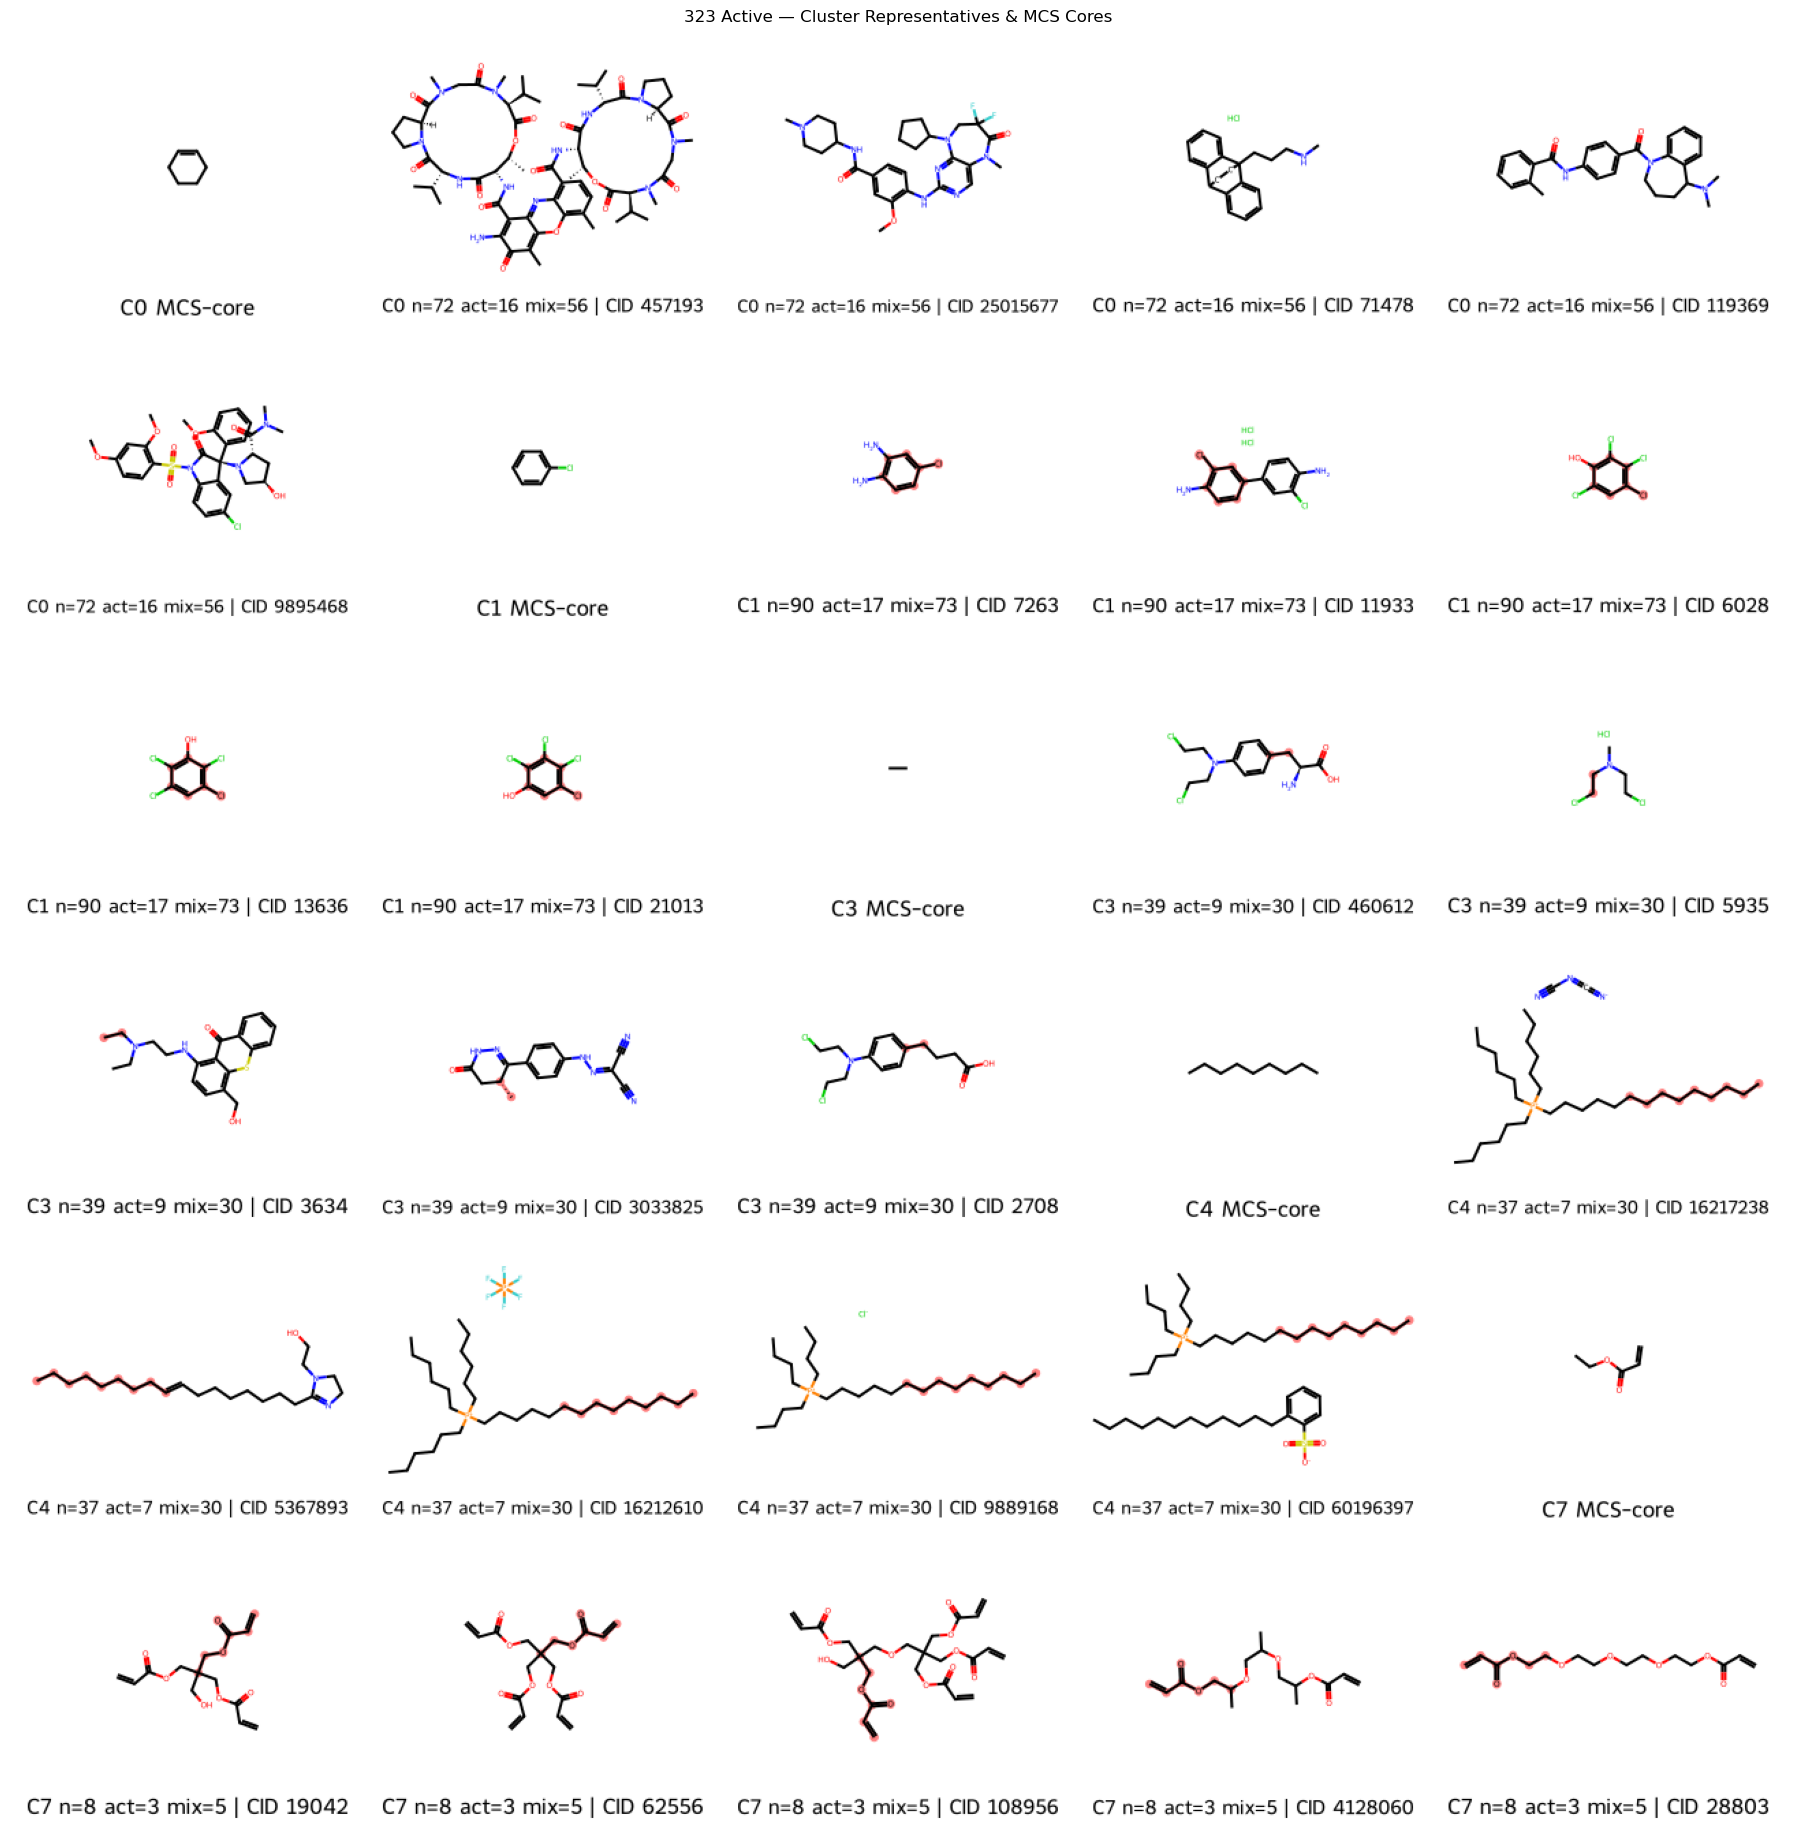

In [68]:
# Select clusters with Active >= 3 (fallback: active_total >= 1)
ae_strict = comp_df[comp_df['Active'] >= 3]['cluster'].tolist()
if len(ae_strict) == 0:
    ae_clusters = comp_df[comp_df['active_total'] >= 1]['cluster'].tolist()
    print(f'Fallback: {len(ae_clusters)} clusters with active_total >= 1')
else:
    ae_clusters = ae_strict
    print(f'{len(ae_clusters)} clusters with Active >= 3')

ae_mask = g323['cluster'].isin(ae_clusters)
ae_data = g323[ae_mask].copy()
print(f'Compounds in selected clusters: {len(ae_data)}')

cl_name_ae = draw_cluster_reps(
    ae_data,
    title='323 Active — Cluster Representatives & MCS Cores',
    mols_per_row=5,
    img_size=(260, 220),
    max_per_cluster=5,
    max_clusters=30,
)

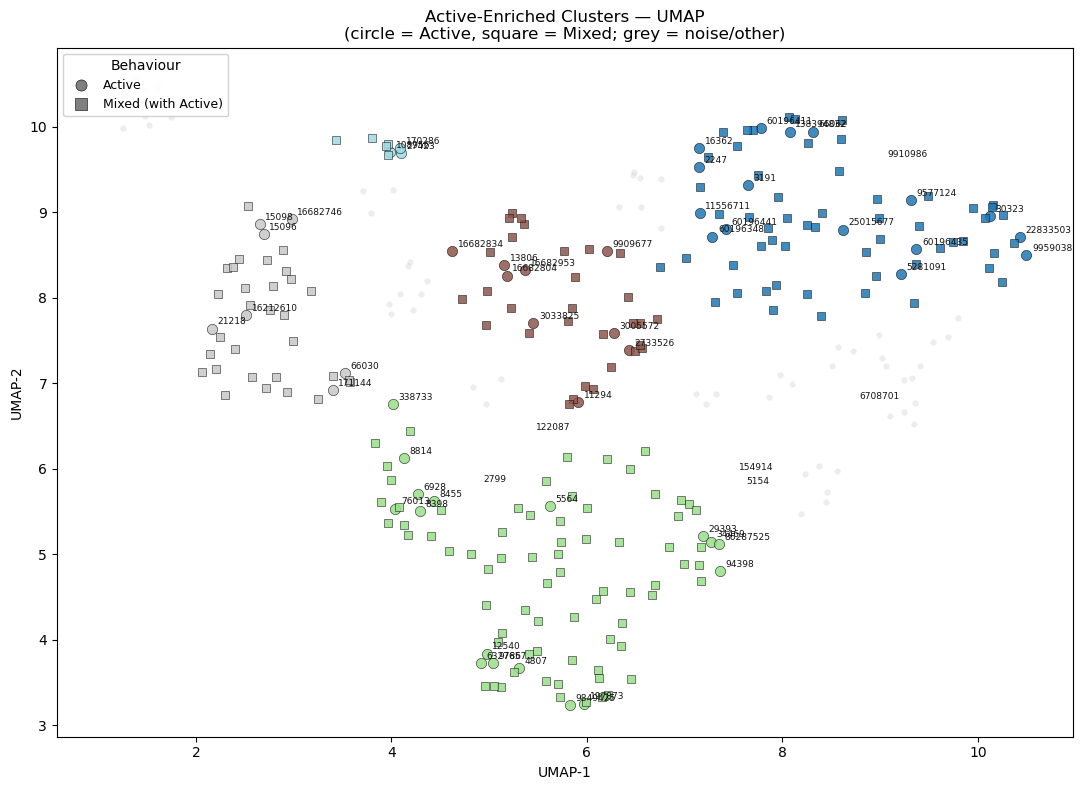

In [69]:
import matplotlib.lines as mlines

MARKER_MAP = {
    'Active':              'o',
    'Mixed (with Active)': 's',
}

fig, ax = plt.subplots(figsize=(11, 8))

# background — noise + non-selected clusters
bg = g323[~ae_mask]
ax.scatter(bg['umap_x'], bg['umap_y'],
           c='lightgrey', s=20, alpha=0.4, linewidths=0, zorder=1,
           label='noise / other clusters')

# foreground — selected clusters, colour by cluster ID
cmap20 = plt.cm.get_cmap('tab20', max(len(cl_name_ae), 1))
for i, cl in enumerate(sorted(cl_name_ae.keys())):
    sub = ae_data[ae_data['cluster'] == cl]
    for cat, marker in MARKER_MAP.items():
        pts = sub[sub['behavior_category'] == cat]
        if len(pts) == 0:
            continue
        ax.scatter(pts['umap_x'], pts['umap_y'],
                   c=[cmap20(i)], s=55 if cat == 'Active' else 35,
                   marker=marker, alpha=0.85,
                   edgecolors='black', linewidths=0.4, zorder=3,
                   label=f'C{cl} — {cat} (n={len(pts)})')

# annotate all Active CIDs in the selected clusters
for _, row in ae_data[ae_data['behavior_category'] == 'Active'].iterrows():
    ax.annotate(str(int(row['PUBCHEM_CID'])),
                (row['umap_x'], row['umap_y']),
                textcoords='offset points', xytext=(4, 3),
                fontsize=6.5, color='#111', zorder=4)

# behaviour-marker legend
marker_handles = [
    mlines.Line2D([], [], color='grey', marker=m,
                  linestyle='None', markersize=8,
                  markeredgecolor='black', markeredgewidth=0.4,
                  label=cat)
    for cat, m in MARKER_MAP.items()
]
ax.legend(handles=marker_handles, loc='upper left', fontsize=9,
          title='Behaviour', framealpha=0.9)
ax.set_title('Active-Enriched Clusters — UMAP\n'
             '(circle = Active, square = Mixed; grey = noise/other)', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
plt.tight_layout(); plt.show()

### MCS Core Detail per Active-Enriched Cluster

For each active-enriched cluster the MCS core scaffold is shown alongside
the molecules closest to the cluster centroid, with the common core highlighted.

── Cluster 0  (n=72, active=16, mixed-active=56) ──


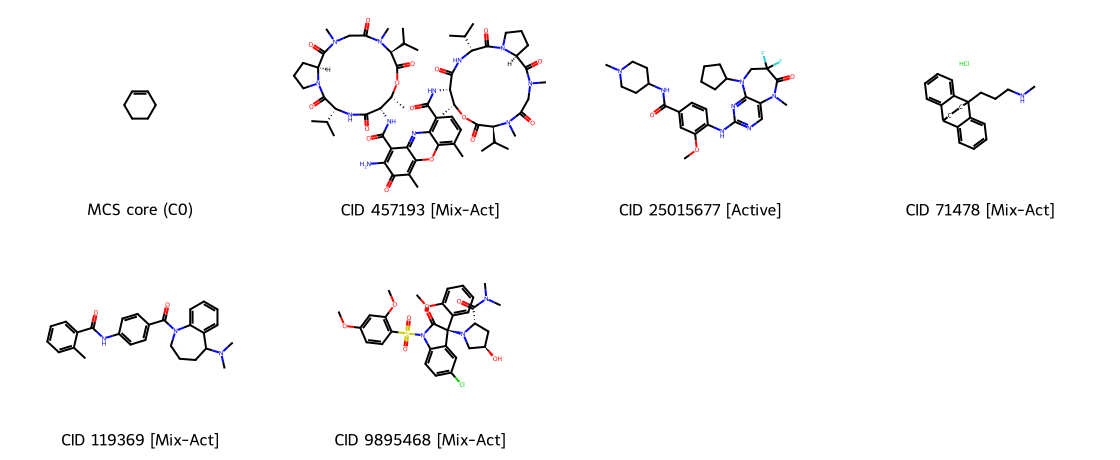


── Cluster 1  (n=90, active=17, mixed-active=73) ──


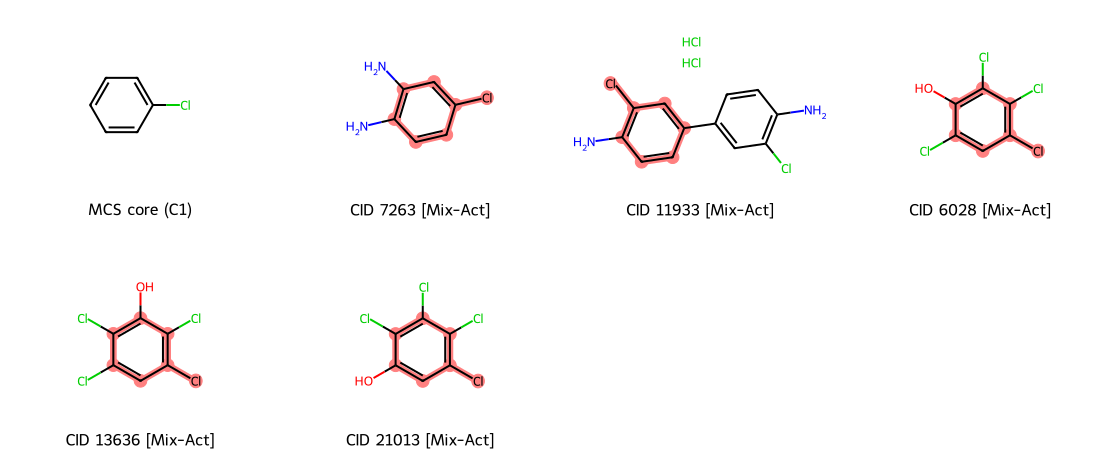


── Cluster 3  (n=39, active=9, mixed-active=30) ──


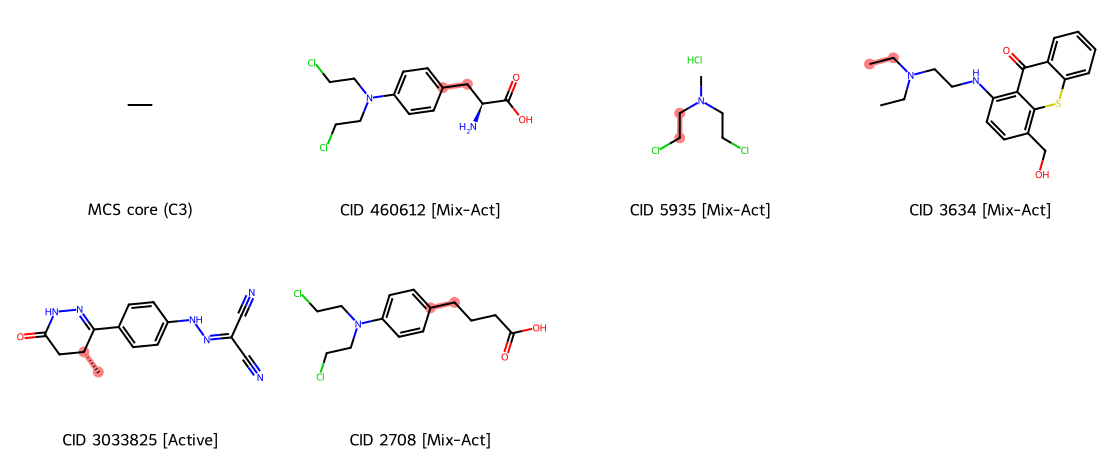


── Cluster 4  (n=37, active=7, mixed-active=30) ──


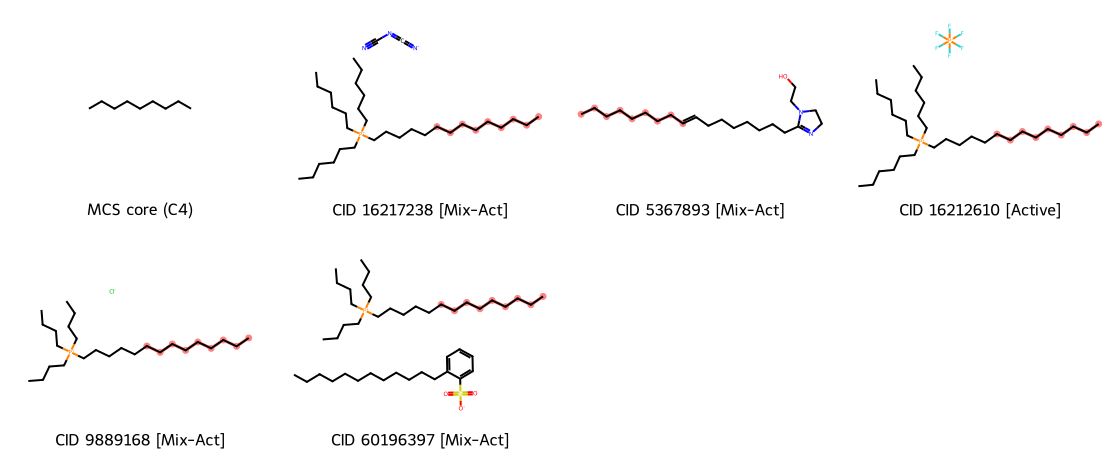


── Cluster 7  (n=8, active=3, mixed-active=5) ──


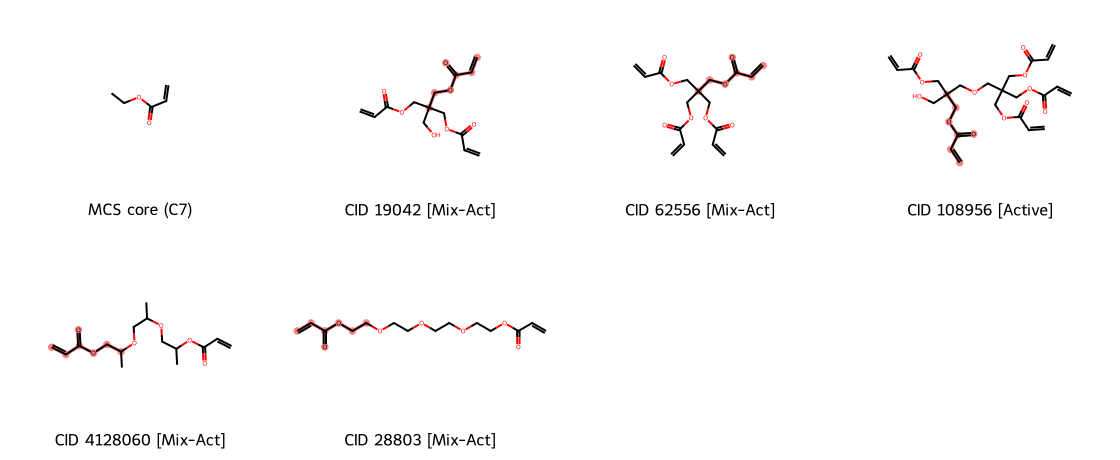

In [70]:
from IPython.display import display

CLUSTERS_DETAIL = None   # None = all; or e.g. [0, 2, 5]
MOLS_PER_ROW    = 4

ids_to_show = sorted(cl_name_ae.keys()) if CLUSTERS_DETAIL is None else CLUSTERS_DETAIL

for cl in ids_to_show:
    sub     = g323[g323['cluster'] == cl].copy()
    central = pick_central(sub, n_min=3, n_max=5)
    mols_c  = [m for m in central['mol'].tolist() if m is not None]
    if not mols_c:
        continue
    core = get_mcs_core(mols_c)

    n_act = (sub['behavior_category'] == 'Active').sum()
    n_mix = (sub['behavior_category'] == 'Mixed (with Active)').sum()
    print(f'── Cluster {cl}  (n={len(sub)}, active={n_act}, mixed-active={n_mix}) ──')

    draw_mols = []
    draw_legs = []
    draw_hi   = []
    if core is not None:
        draw_mols.append(core)
        draw_legs.append(f'MCS core (C{cl})')
        draw_hi.append([])
    for _, row in central.iterrows():
        if row['mol'] is None:
            continue
        cat_short = row['behavior_category'].replace(
            'Mixed (with Active)', 'Mix-Act')
        draw_mols.append(row['mol'])
        draw_legs.append(f'CID {int(row["PUBCHEM_CID"])} [{cat_short}]')
        match = row['mol'].GetSubstructMatch(core) if core is not None else []
        draw_hi.append(list(match))

    if draw_mols:
        img = Draw.MolsToGridImage(
            draw_mols, molsPerRow=MOLS_PER_ROW, subImgSize=(280, 230),
            legends=draw_legs, highlightAtomLists=draw_hi,
            returnPNG=False)
        display(img)
    print()

---
## Section 5 — Full UMAP Coloured by Cluster

All 323 active compounds coloured by their DBSCAN cluster assignment.
Noise points (label = −1) appear in light grey.

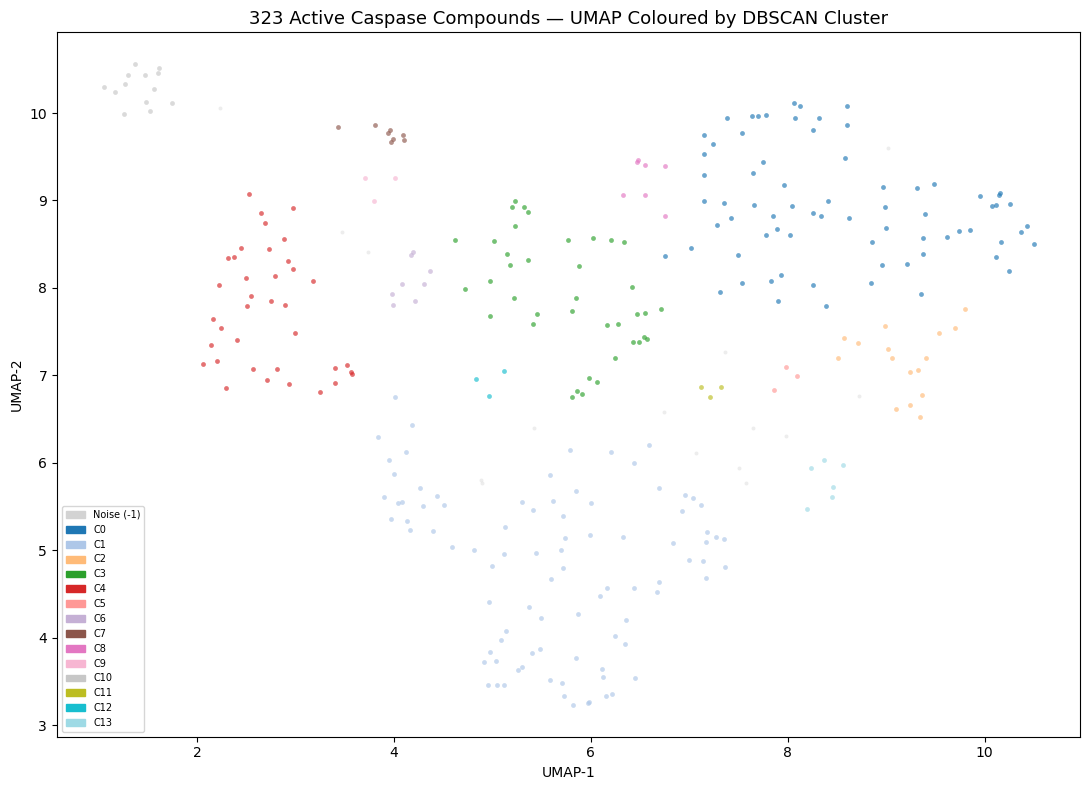

In [71]:
cl_name_all = {cl: f'C{cl}' for cl in g323['cluster'].unique() if cl != -1}
umap_by_cluster(
    g323, cl_name_all,
    title='323 Active Caspase Compounds — UMAP Coloured by DBSCAN Cluster')